In [82]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv(
    r"C:\Users\kavee\Downloads\ChargingRecords.csv"
)

print("Dataset Loaded Successfully!")
print("Dataset Shape:", df.shape)

display(df.head())

Dataset Loaded Successfully!
Dataset Shape: (72856, 13)


,UserID,ChargerID,ChargerCompany,Location,ChargerType,StartDay,StartTime,EndDay,EndTime,StartDatetime,EndDatetime,Duration,Demand
0,0,1,1,hotel,0,2022-09-15,20:54:02,2022-09-15,23:59:13,2022-09-15 20:54,2022-09-15 23:59,185,20.36
1,0,1,1,hotel,0,2022-09-14,20:01:05,2022-09-14,21:31:04,2022-09-14 20:01,2022-09-14 21:31,90,10.19
2,0,1,1,hotel,0,2022-09-14,18:54:30,2022-09-14,19:54:29,2022-09-14 18:54,2022-09-14 19:54,60,6.78
3,0,1,1,hotel,0,2022-09-29,18:32:51,2022-09-30,0:16:42,2022-09-29 18:32,2022-09-30 0:16,344,37.65
4,0,1,1,hotel,0,2022-09-25,19:30:15,2022-09-26,0:30:14,2022-09-25 19:30,2022-09-26 0:30,300,33.81


In [83]:
print("Available Columns:")
print(df.columns.tolist())

print("\nMissing Values:")
print(df.isnull().sum())

Available Columns:
['UserID', 'ChargerID', 'ChargerCompany', 'Location', 'ChargerType', 'StartDay', 'StartTime', 'EndDay', 'EndTime', 'StartDatetime', 'EndDatetime', 'Duration', 'Demand']

Missing Values:
UserID            0
ChargerID         0
ChargerCompany    0
Location          0
ChargerType       0
StartDay          0
StartTime         0
EndDay            0
EndTime           0
StartDatetime     0
EndDatetime       0
Duration          0
Demand            0
dtype: int64


In [84]:
import os

print("Notebook Working Directory:")
print(os.getcwd())

print("\nParent Folder Contents:")
print(os.listdir(".."))

Notebook Working Directory:
c:\Users\kavee\OneDrive\Desktop\EV Charging Demand Prediction and Usage Pattern Analysis\notebook

Parent Folder Contents:
['01_data_understanding.ipynb', '02_data_cleaning.ipynb', '03_eda.ipynb', '04_feature_engineering.ipynb', '05_regression_model.ipynb', '06_classification_model.ipynb', '07_model_explainability.ipynb', 'ChargingRecords.csv', 'classification_model_results.csv', 'data', 'models', 'notebook', 'outputs', 'reports', 'streamlit']


In [85]:


df["StartDatetime"] = pd.to_datetime(
    df["StartDatetime"],
    errors="coerce"
)

df["Demand"] = pd.to_numeric(
    df["Demand"],
    errors="coerce"
)

ts_df = df.dropna(
    subset=["StartDatetime", "Demand"]
).copy()

ts_df = ts_df.sort_values(
    by="StartDatetime"
)

ts_df = ts_df.set_index("StartDatetime")

print("Time-Series Data Prepared Successfully!")
print("Total Records:", len(ts_df))
print("Start Date:", ts_df.index.min())
print("End Date:", ts_df.index.max())

display(ts_df[["Demand"]].head())

Time-Series Data Prepared Successfully!
Total Records: 72856
Start Date: 2021-09-30 17:14:00
End Date: 2022-09-30 23:11:00


,Demand
StartDatetime,
2021-09-30 17:14:00,27.68
2021-09-30 18:22:00,55.13
2021-09-30 18:57:00,38.45
2021-09-30 19:52:00,30.17
2021-09-30 20:48:00,47.00


In [86]:

daily_demand = (
    ts_df["Demand"]
    .resample("D")
    .sum()
    .reset_index()
)

daily_demand.columns = [
    "Date",
    "DailyDemand"
]

print("Daily Demand Analysis Completed!")
print("Total Days:", len(daily_demand))

display(daily_demand.head(10))

print("\nDaily Demand Statistics:")
display(daily_demand["DailyDemand"].describe())

Daily Demand Analysis Completed!
Total Days: 366


,Date,DailyDemand
0,2021-09-30,579.19
1,2021-10-01,2467.59
2,2021-10-02,2087.75
3,2021-10-03,1928.25
4,2021-10-04,1768.66
5,2021-10-05,2530.86
6,2021-10-06,2300.17
7,2021-10-07,2113.15
8,2021-10-08,2266.41
9,2021-10-09,1688.26



Daily Demand Statistics:


count     366.000000
mean     3472.493224
std       875.473475
min       579.190000
25%      2795.702500
50%      3548.975000
75%      4070.535000
max      5879.910000
Name: DailyDemand, dtype: float64

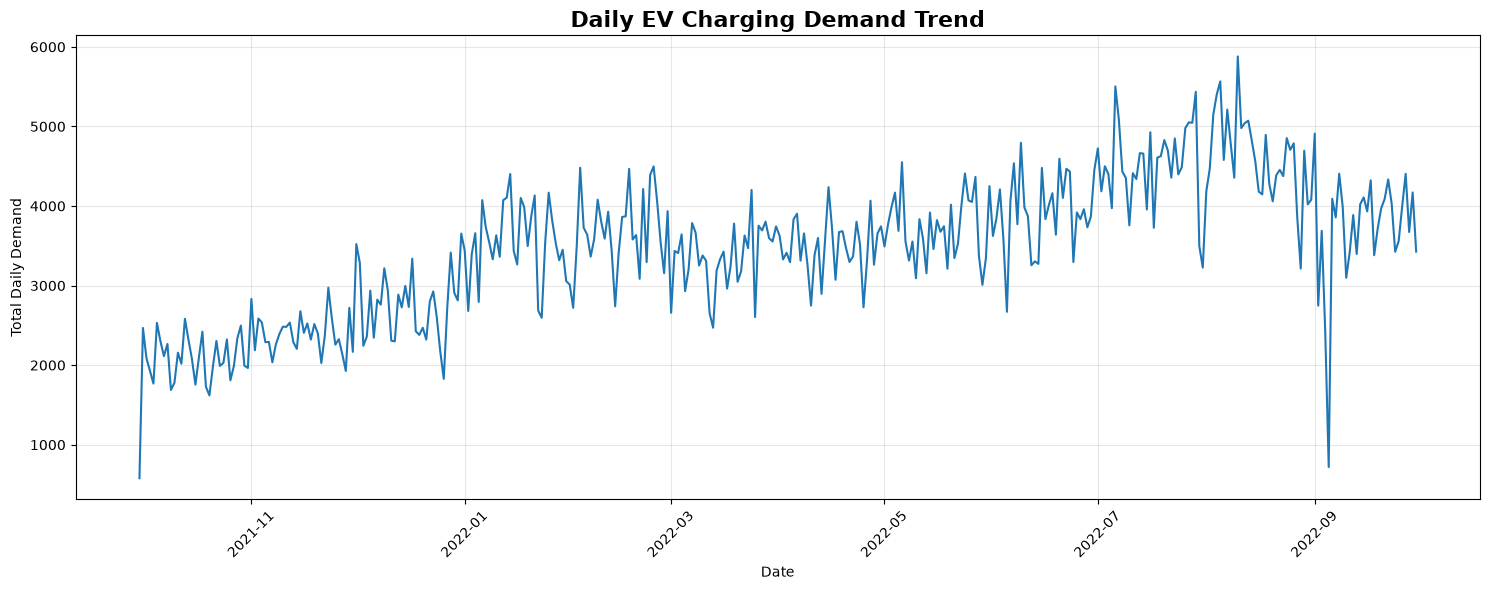

In [87]:


plt.figure(figsize=(15, 6))

plt.plot(
    daily_demand["Date"],
    daily_demand["DailyDemand"],
    linewidth=1.5
)

plt.title(
    "Daily EV Charging Demand Trend",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Date")
plt.ylabel("Total Daily Demand")

plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [88]:


weekly_demand = (
    ts_df["Demand"]
    .resample("W")
    .sum()
    .reset_index()
)

weekly_demand.columns = [
    "Week",
    "WeeklyDemand"
]

print("Weekly Demand Analysis Completed!")
print("Total Weeks:", len(weekly_demand))

display(weekly_demand.head(10))

print("\nWeekly Demand Statistics:")
display(weekly_demand["WeeklyDemand"].describe())

Weekly Demand Analysis Completed!
Total Weeks: 53


,Week,WeeklyDemand
0,2021-10-03,7062.78
1,2021-10-10,14445.68
2,2021-10-17,15012.11
3,2021-10-24,14073.62
4,2021-10-31,14918.48
5,2021-11-07,16756.46
6,2021-11-14,16644.91
7,2021-11-21,16869.86
8,2021-11-28,16583.06
9,2021-12-05,19235.13



Weekly Demand Statistics:


count       53.000000
mean     23979.858868
std       5706.819199
min       7062.780000
25%      19670.130000
50%      24807.150000
75%      27123.010000
max      34929.210000
Name: WeeklyDemand, dtype: float64

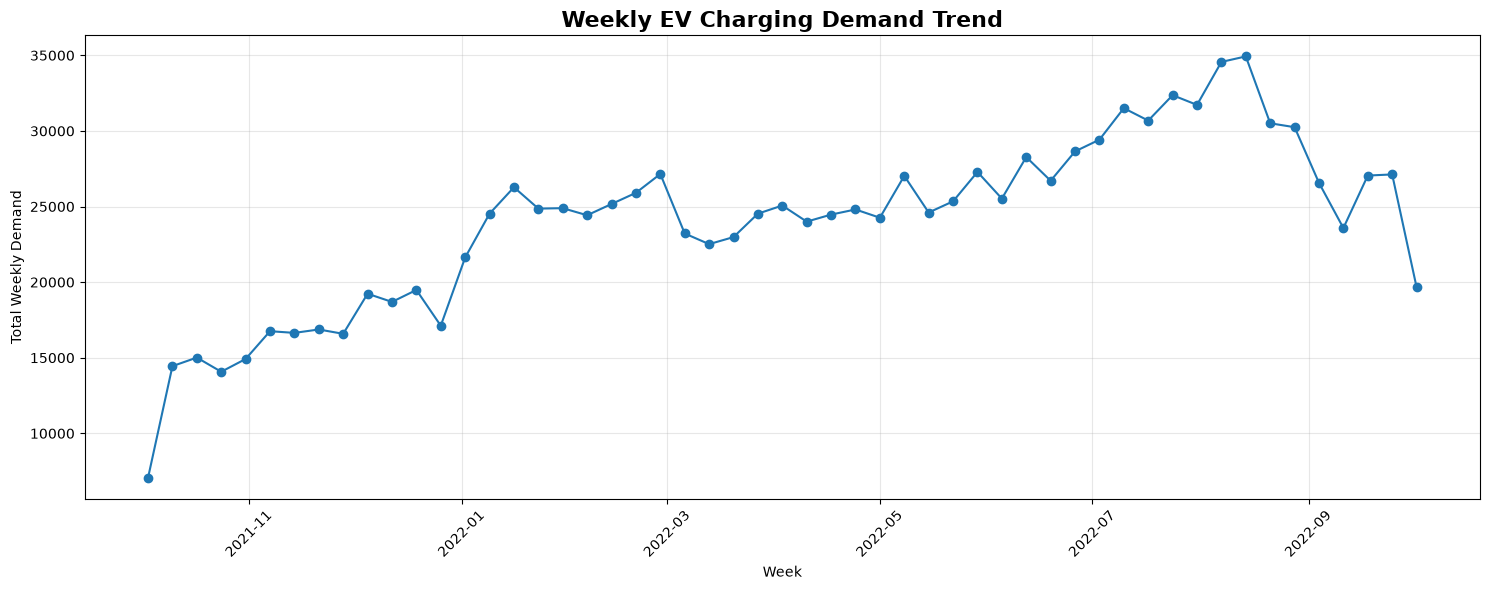

In [89]:

plt.figure(figsize=(15, 6))

plt.plot(
    weekly_demand["Week"],
    weekly_demand["WeeklyDemand"],
    marker="o",
    linewidth=1.5
)

plt.title(
    "Weekly EV Charging Demand Trend",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Week")
plt.ylabel("Total Weekly Demand")

plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [90]:



monthly_demand = (
    ts_df["Demand"]
    .resample("MS")
    .sum()
    .reset_index()
)

monthly_demand.columns = [
    "Month",
    "MonthlyDemand"
]

print("Monthly Demand Analysis Completed!")
print("Total Months:", len(monthly_demand))

display(monthly_demand)

print("\nMonthly Demand Statistics:")
display(monthly_demand["MonthlyDemand"].describe())

Monthly Demand Analysis Completed!
Total Months: 13


,Month,MonthlyDemand
0,2021-09-01,579.19
1,2021-10-01,64933.48
2,2021-11-01,71741.55
3,2021-12-01,85158.09
4,2022-01-01,109688.78
5,2022-02-01,103576.10
6,2022-03-01,104003.60
7,2022-04-01,104414.29
8,2022-05-01,115352.49
9,2022-06-01,117564.42



Monthly Demand Statistics:


count        13.000000
mean      97764.040000
std       36863.742349
min         579.190000
25%       85158.090000
50%      104414.290000
75%      115352.490000
max      143041.270000
Name: MonthlyDemand, dtype: float64

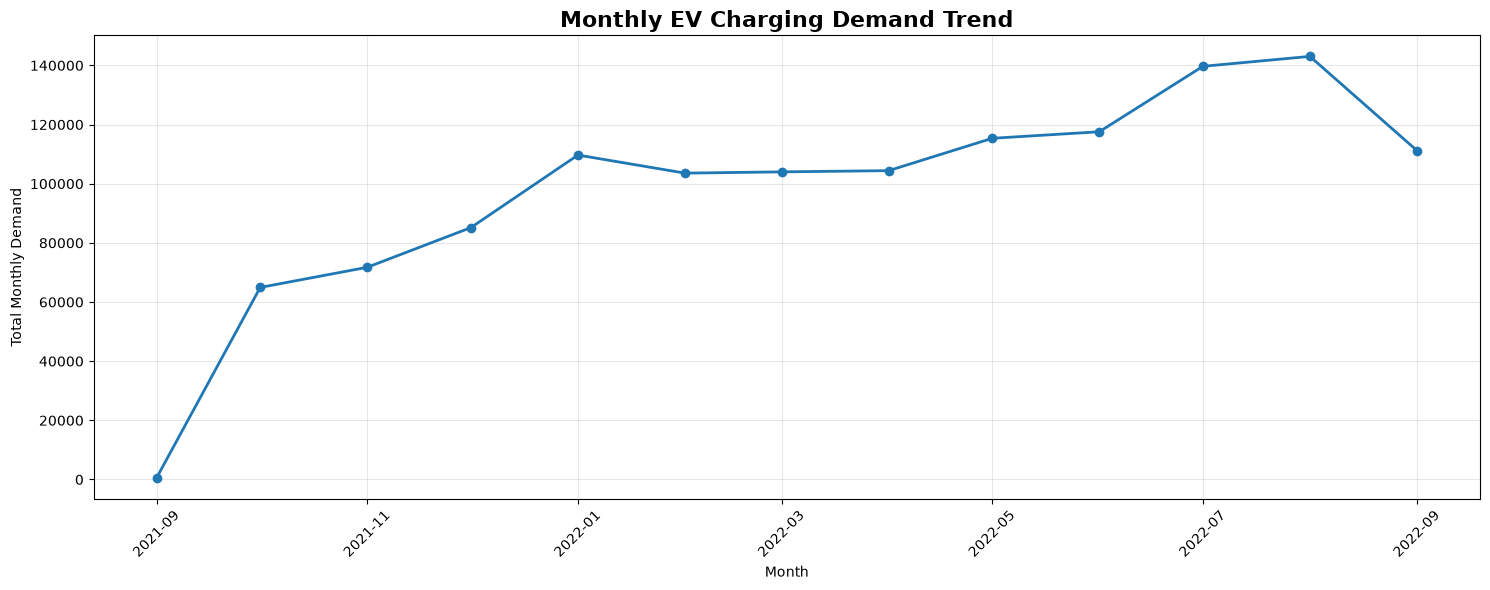

In [91]:


plt.figure(figsize=(15, 6))

plt.plot(
    monthly_demand["Month"],
    monthly_demand["MonthlyDemand"],
    marker="o",
    linewidth=2
)

plt.title(
    "Monthly EV Charging Demand Trend",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Month")
plt.ylabel("Total Monthly Demand")

plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [92]:


hourly_df = ts_df.copy()

hourly_df["Hour"] = hourly_df.index.hour

hourly_demand = (
    hourly_df.groupby("Hour")["Demand"]
    .sum()
    .reset_index()
)

hourly_demand.columns = [
    "Hour",
    "TotalDemand"
]

print("Hourly Demand Analysis Completed!")

display(hourly_demand)

print("\nPeak Demand Hour:")
display(
    hourly_demand.loc[
        hourly_demand["TotalDemand"].idxmax()
    ]
)

Hourly Demand Analysis Completed!


,Hour,TotalDemand
0,0,24396.87
1,1,11368.29
2,2,5007.37
3,3,2713.46
4,4,3469.31
5,5,9467.91
6,6,20669.05
7,7,38568.03
8,8,72574.42
9,9,58474.12



Peak Demand Hour:


Hour               18.00
TotalDemand    119495.53
Name: 18, dtype: float64

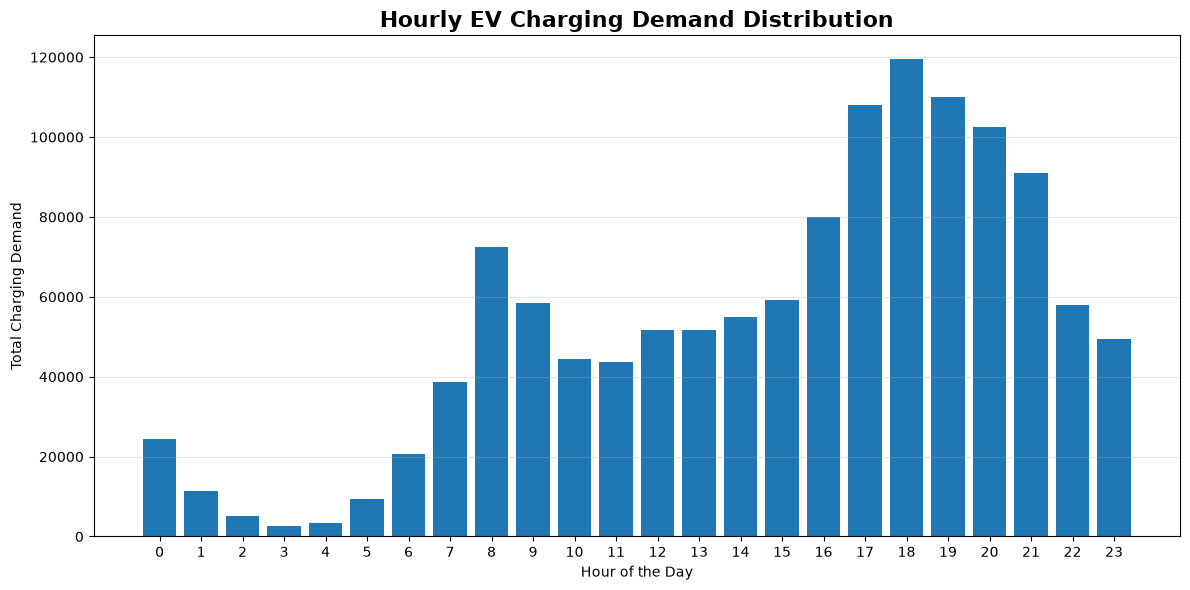

In [93]:


plt.figure(figsize=(12, 6))

plt.bar(
    hourly_demand["Hour"],
    hourly_demand["TotalDemand"]
)

plt.title(
    "Hourly EV Charging Demand Distribution",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Hour of the Day")
plt.ylabel("Total Charging Demand")

plt.xticks(range(0, 24))
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [94]:

print("=" * 55)
print("EV CHARGING TIME-SERIES ANALYSIS SUMMARY")
print("=" * 55)

print("Total Charging Records:", len(ts_df))
print("Analysis Start Date:", ts_df.index.min())
print("Analysis End Date:", ts_df.index.max())

print("Total Days Analyzed:", len(daily_demand))
print("Total Weeks Analyzed:", len(weekly_demand))
print("Total Months Analyzed:", len(monthly_demand))

print("Peak Demand Hour:",
      int(hourly_demand.loc[
          hourly_demand["TotalDemand"].idxmax(), "Hour"
      ]))

print("\nTime-Series Analysis Completed Successfully!")

EV CHARGING TIME-SERIES ANALYSIS SUMMARY
Total Charging Records: 72856
Analysis Start Date: 2021-09-30 17:14:00
Analysis End Date: 2022-09-30 23:11:00
Total Days Analyzed: 366
Total Weeks Analyzed: 53
Total Months Analyzed: 13
Peak Demand Hour: 18

Time-Series Analysis Completed Successfully!


In [95]:


forecast_df = daily_demand.copy()

forecast_df["Date"] = pd.to_datetime(
    forecast_df["Date"],
    errors="coerce"
)

forecast_df["DailyDemand"] = pd.to_numeric(
    forecast_df["DailyDemand"],
    errors="coerce"
)

forecast_df = forecast_df.dropna(
    subset=["Date", "DailyDemand"]
)

forecast_df = forecast_df.sort_values("Date")

forecast_df = forecast_df.drop_duplicates(
    subset=["Date"],
    keep="last"
)

forecast_df = forecast_df.set_index("Date")

# Ensure continuous daily frequency
forecast_df = forecast_df.asfreq("D")

# Fill missing daily demand with zero
forecast_df["DailyDemand"] = forecast_df["DailyDemand"].fillna(0)

print("Forecasting Dataset Prepared Successfully!")
print("Total Days:", len(forecast_df))
print("Start Date:", forecast_df.index.min())
print("End Date:", forecast_df.index.max())

display(forecast_df.head(10))

print("\nForecasting Dataset Statistics:")
display(forecast_df["DailyDemand"].describe())

if len(forecast_df) < 30:
    print("\nWARNING: Limited historical data for reliable forecasting.")
else:
    print("\nSufficient historical records for the next forecasting steps.")

Forecasting Dataset Prepared Successfully!
Total Days: 366
Start Date: 2021-09-30 00:00:00
End Date: 2022-09-30 00:00:00


,DailyDemand
Date,
2021-09-30,579.19
2021-10-01,2467.59
2021-10-02,2087.75
2021-10-03,1928.25
2021-10-04,1768.66
2021-10-05,2530.86
2021-10-06,2300.17
2021-10-07,2113.15
2021-10-08,2266.41



Forecasting Dataset Statistics:


count     366.000000
mean     3472.493224
std       875.473475
min       579.190000
25%      2795.702500
50%      3548.975000
75%      4070.535000
max      5879.910000
Name: DailyDemand, dtype: float64


Sufficient historical records for the next forecasting steps.


In [96]:

model_df = forecast_df.copy()

# Historical demand features
model_df["Lag_1"] = model_df["DailyDemand"].shift(1)
model_df["Lag_7"] = model_df["DailyDemand"].shift(7)
model_df["Lag_14"] = model_df["DailyDemand"].shift(14)

# Rolling average features (past data only)
model_df["Rolling_Mean_7"] = (
    model_df["DailyDemand"]
    .shift(1)
    .rolling(window=7)
    .mean()
)

model_df["Rolling_Mean_14"] = (
    model_df["DailyDemand"]
    .shift(1)
    .rolling(window=14)
    .mean()
)

# Calendar-based features
model_df["DayOfWeek"] = model_df.index.dayofweek
model_df["Month"] = model_df.index.month
model_df["DayOfYear"] = model_df.index.dayofyear

# Remove rows with missing lag values
model_df = model_df.dropna()

print("Time-Series Features Created Successfully!")
print("Feature Dataset Shape:", model_df.shape)

display(model_df.head(10))

print("\nAvailable Features:")
print(model_df.columns.tolist())

Time-Series Features Created Successfully!
Feature Dataset Shape: (352, 9)


,DailyDemand,Lag_1,Lag_7,Lag_14,Rolling_Mean_7,Rolling_Mean_14,DayOfWeek,Month,DayOfYear
Date,,,,,,,,,
2021-10-14,2323.78,2582.10,2113.15,579.19,2086.105714,2018.943571,3,10,287
2021-10-15,2079.50,2323.78,2266.41,2467.59,2116.195714,2143.557143,4,10,288
2021-10-16,1755.11,2079.50,1688.26,2087.75,2089.494286,2115.836429,5,10,289
2021-10-17,2096.97,1755.11,1778.17,1928.25,2099.044286,2092.076429,6,10,290
2021-10-18,2421.27,2096.97,2157.08,1768.66,2144.587143,2104.127857,0,10,291
2021-10-19,1729.23,2421.27,2017.57,2530.86,2182.328571,2150.742857,1,10,292
2021-10-20,1619.44,1729.23,2582.10,2300.17,2141.137143,2093.483571,2,10,293
2021-10-21,1980.87,1619.44,2323.78,2113.15,2003.614286,2044.860000,3,10,294
2021-10-22,2304.45,1980.87,2079.50,2266.41,1954.627143,2035.411429,4,10,295



Available Features:
['DailyDemand', 'Lag_1', 'Lag_7', 'Lag_14', 'Rolling_Mean_7', 'Rolling_Mean_14', 'DayOfWeek', 'Month', 'DayOfYear']


In [97]:

from sklearn.model_selection import train_test_split

# Separate features and target
X = model_df.drop(columns=["DailyDemand"])
y = model_df["DailyDemand"]

# Chronological 80:20 split
split_index = int(len(model_df) * 0.80)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Chronological Data Split Completed!")
print("-" * 45)

print("Training Records:", len(X_train))
print("Testing Records:", len(X_test))

print("\nTraining Period:")
print(X_train.index.min(), "to", X_train.index.max())

print("\nTesting Period:")
print(X_test.index.min(), "to", X_test.index.max())

print("\nTraining Features Shape:", X_train.shape)
print("Testing Features Shape:", X_test.shape)

Chronological Data Split Completed!
---------------------------------------------
Training Records: 281
Testing Records: 71

Training Period:
2021-10-14 00:00:00 to 2022-07-21 00:00:00

Testing Period:
2022-07-22 00:00:00 to 2022-09-30 00:00:00

Training Features Shape: (281, 8)
Testing Features Shape: (71, 8)


In [98]:


from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

# Random Forest Model
rf_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=10,
    min_samples_split=5,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

print("Random Forest Model Trained Successfully!")

# XGBoost Model
xgb_model = XGBRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=5,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42
)

xgb_model.fit(X_train, y_train)

print("XGBoost Model Trained Successfully!")

print("\nBoth Forecasting Models Training Completed!")

Random Forest Model Trained Successfully!
XGBoost Model Trained Successfully!

Both Forecasting Models Training Completed!


In [99]:


from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np
import pandas as pd

# Generate predictions
rf_predictions = rf_model.predict(X_test)
xgb_predictions = xgb_model.predict(X_test)

# Evaluation function
def evaluate_forecast_model(model_name, actual, predicted):

    mae = mean_absolute_error(actual, predicted)
    mse = mean_squared_error(actual, predicted)
    rmse = np.sqrt(mse)
    r2 = r2_score(actual, predicted)

    return {
        "Model": model_name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2 Score": r2
    }

# Compare both models
forecast_results = pd.DataFrame([
    evaluate_forecast_model(
        "Random Forest", y_test, rf_predictions
    ),
    evaluate_forecast_model(
        "XGBoost", y_test, xgb_predictions
    )
])

print("Forecasting Model Evaluation Results")
display(forecast_results.round(4))

# Select best model based on lowest RMSE
best_model_name = forecast_results.loc[
    forecast_results["RMSE"].idxmin(), "Model"
]

best_forecast_model = (
    rf_model if best_model_name == "Random Forest"
    else xgb_model
)

print("\nBest Forecasting Model:", best_model_name)
print("Selection Metric: Lowest RMSE")

Forecasting Model Evaluation Results


,Model,MAE,MSE,RMSE,R2 Score
0,Random Forest,483.8042,447345.5332,668.8389,0.2762
1,XGBoost,527.3083,576116.2218,759.0232,0.0678



Best Forecasting Model: Random Forest
Selection Metric: Lowest RMSE


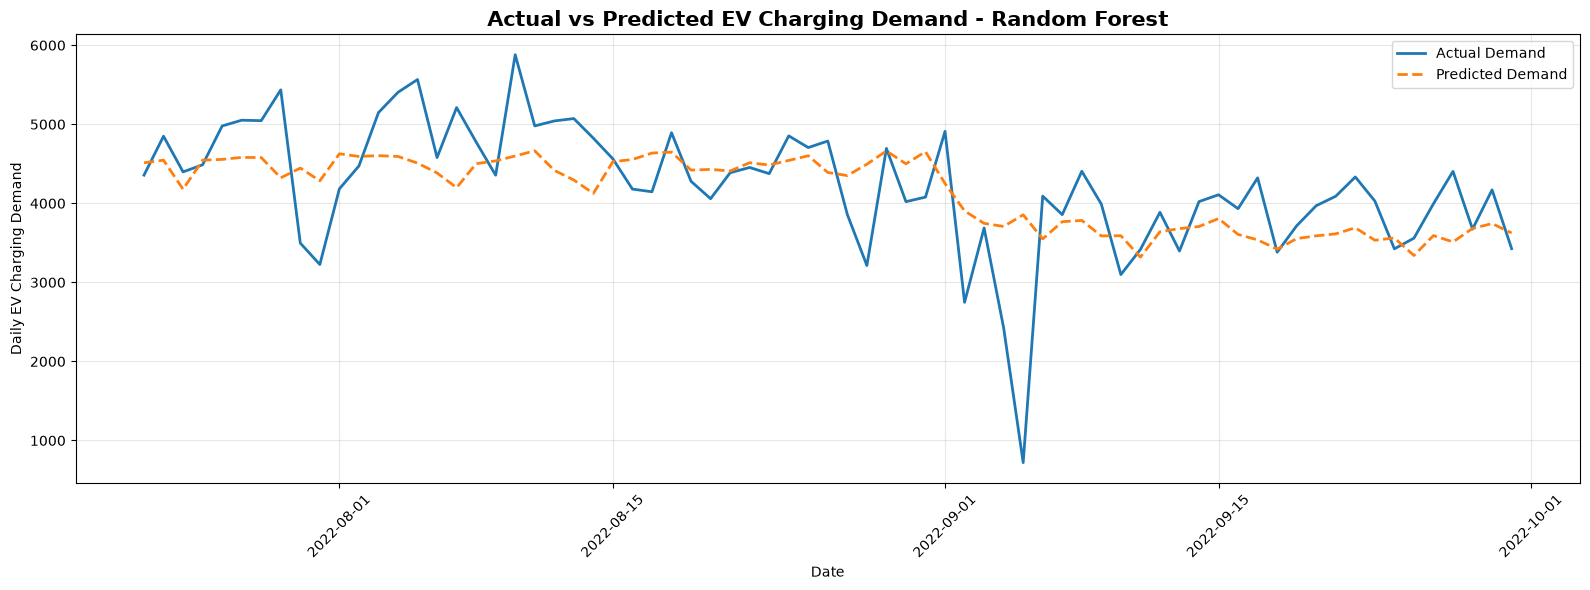

Actual vs Predicted Demand Visualization Completed!


In [100]:


plt.figure(figsize=(16, 6))

plt.plot(
    y_test.index,
    y_test.values,
    label="Actual Demand",
    linewidth=2
)

plt.plot(
    y_test.index,
    best_forecast_model.predict(X_test),
    label="Predicted Demand",
    linewidth=2,
    linestyle="--"
)

plt.title(
    f"Actual vs Predicted EV Charging Demand - {best_model_name}",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Date")
plt.ylabel("Daily EV Charging Demand")

plt.legend()
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("Actual vs Predicted Demand Visualization Completed!")

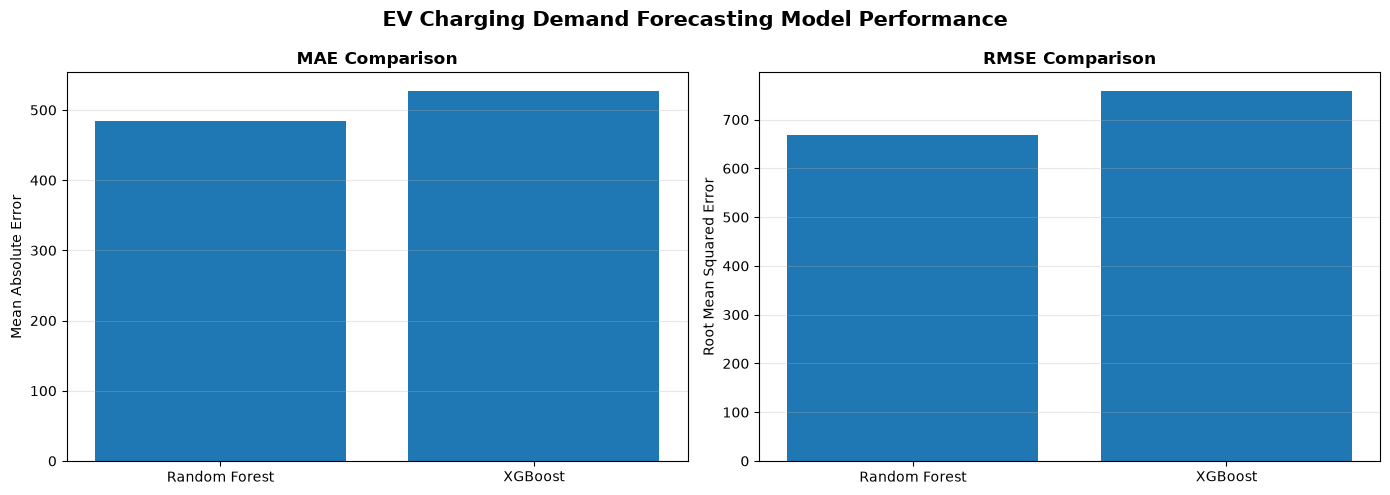

Forecasting Model Comparison Completed!
Best Model: Random Forest


In [101]:

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# MAE Comparison
axes[0].bar(
    forecast_results["Model"],
    forecast_results["MAE"]
)

axes[0].set_title("MAE Comparison", fontweight="bold")
axes[0].set_ylabel("Mean Absolute Error")
axes[0].grid(axis="y", alpha=0.3)

# RMSE Comparison
axes[1].bar(
    forecast_results["Model"],
    forecast_results["RMSE"]
)

axes[1].set_title("RMSE Comparison", fontweight="bold")
axes[1].set_ylabel("Root Mean Squared Error")
axes[1].grid(axis="y", alpha=0.3)

plt.suptitle(
    "EV Charging Demand Forecasting Model Performance",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

print("Forecasting Model Comparison Completed!")
print("Best Model:", best_model_name)

In [102]:

# Use the complete historical demand series
history = forecast_df["DailyDemand"].copy()

future_predictions = []

# Generate next 7 dates
future_dates = pd.date_range(
    start=history.index.max() + pd.Timedelta(days=1),
    periods=7,
    freq="D"
)

feature_columns = X_train.columns.tolist()

# Recursive forecasting
for future_date in future_dates:

    features = {
        "Lag_1": history.iloc[-1],
        "Lag_7": history.iloc[-7],
        "Lag_14": history.iloc[-14],
        "Rolling_Mean_7": history.iloc[-7:].mean(),
        "Rolling_Mean_14": history.iloc[-14:].mean(),
        "DayOfWeek": future_date.dayofweek,
        "Month": future_date.month,
        "DayOfYear": future_date.dayofyear
    }

    future_input = pd.DataFrame(
        [features],
        columns=feature_columns
    )

    predicted_demand = best_forecast_model.predict(
        future_input
    )[0]

    predicted_demand = max(0, predicted_demand)

    future_predictions.append(predicted_demand)

    # Add prediction to history for next-day forecasting
    history.loc[future_date] = predicted_demand

# Create forecast results
future_forecast = pd.DataFrame({
    "Date": future_dates,
    "PredictedDemand": future_predictions
})

print("Future 7 Days Forecast Generated Successfully!")
print("Selected Model:", best_model_name)

display(future_forecast.round(2))

Future 7 Days Forecast Generated Successfully!
Selected Model: Random Forest


C:\Users\kavee\AppData\Local\Temp\ipykernel_17852\3181442703.py:54: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(future_forecast.round(2))


,Date,PredictedDemand
0,2022-10-01,3630.41
1,2022-10-02,3422.44
2,2022-10-03,3605.65
3,2022-10-04,3678.29
4,2022-10-05,3686.32
5,2022-10-06,3732.27
6,2022-10-07,3595.31


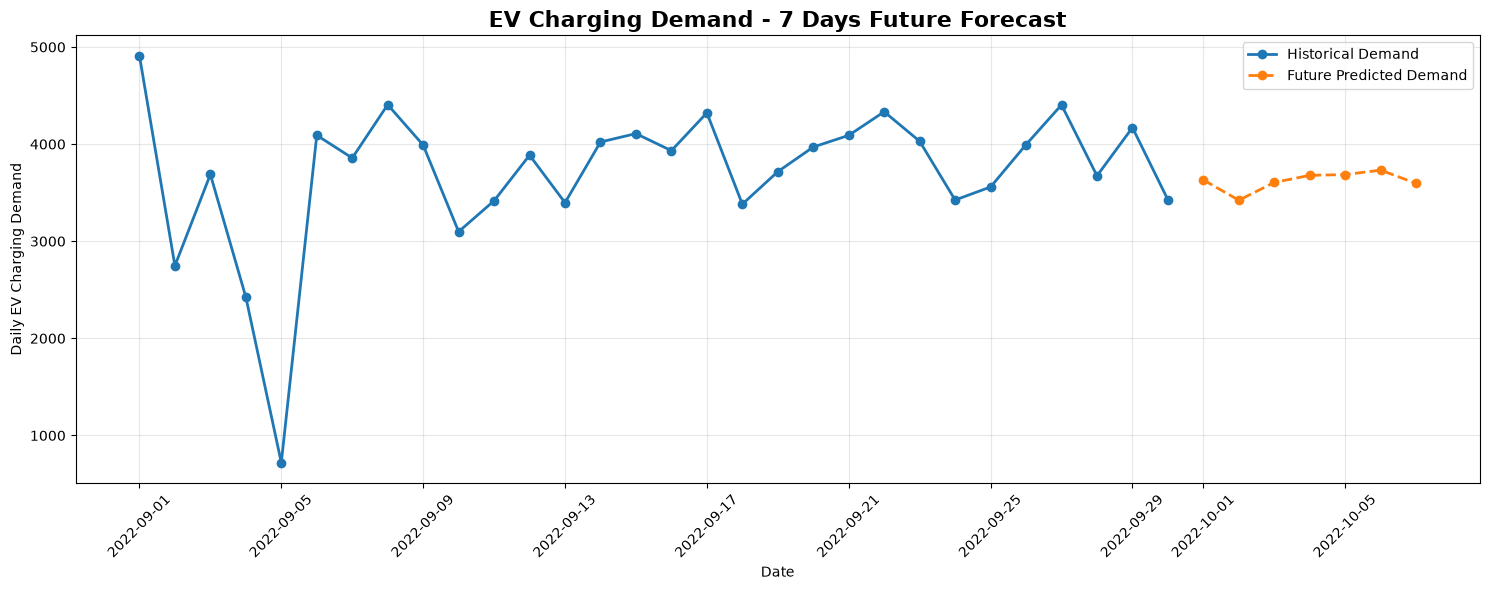

Future Demand Forecast Visualization Completed!


In [103]:

plt.figure(figsize=(15, 6))

# Historical demand
plt.plot(
    forecast_df.index[-30:],
    forecast_df["DailyDemand"].tail(30),
    label="Historical Demand",
    marker="o",
    linewidth=2
)

# Future predicted demand
plt.plot(
    future_forecast["Date"],
    future_forecast["PredictedDemand"],
    label="Future Predicted Demand",
    marker="o",
    linestyle="--",
    linewidth=2
)

plt.title(
    "EV Charging Demand - 7 Days Future Forecast",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Date")
plt.ylabel("Daily EV Charging Demand")

plt.legend()
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("Future Demand Forecast Visualization Completed!")

In [108]:


from pathlib import Path

# Project root directory
PROJECT_DIR = Path.cwd()

# Find project root using dataset file
if not (PROJECT_DIR / "ChargingRecords.csv").exists():

    possible_roots = [
        PROJECT_DIR,
        PROJECT_DIR.parent,
        PROJECT_DIR.parent.parent
    ]

    for root in possible_roots:
        if (root / "ChargingRecords.csv").exists():
            PROJECT_DIR = root
            break

# Create outputs directory
OUTPUT_DIR = PROJECT_DIR / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Forecast CSV path
forecast_file_path = (
    OUTPUT_DIR / "future_demand_forecast.csv"
)

# Save forecast
future_forecast.to_csv(
    forecast_file_path,
    index=False
)

# Verify saved file
if forecast_file_path.exists():

    print("=" * 55)
    print("FUTURE DEMAND FORECAST SAVED SUCCESSFULLY!")
    print("=" * 55)

    print("Project Directory:", PROJECT_DIR.resolve())
    print("Output Directory:", OUTPUT_DIR.resolve())
    print("Forecast File:", forecast_file_path.resolve())
    print("Forecast Shape:", future_forecast.shape)

    print("\nForecast Data:")
    display(future_forecast.round(2))

else:
    print("ERROR: Forecast CSV could not be saved!")

FUTURE DEMAND FORECAST SAVED SUCCESSFULLY!
Project Directory: C:\Users\kavee\OneDrive\Desktop\EV Charging Demand Prediction and Usage Pattern Analysis
Output Directory: C:\Users\kavee\OneDrive\Desktop\EV Charging Demand Prediction and Usage Pattern Analysis\outputs
Forecast File: C:\Users\kavee\OneDrive\Desktop\EV Charging Demand Prediction and Usage Pattern Analysis\outputs\future_demand_forecast.csv
Forecast Shape: (7, 2)

Forecast Data:


C:\Users\kavee\AppData\Local\Temp\ipykernel_17852\599438553.py:48: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(future_forecast.round(2))


,Date,PredictedDemand
0,2022-10-01,3630.41
1,2022-10-02,3422.44
2,2022-10-03,3605.65
3,2022-10-04,3678.29
4,2022-10-05,3686.32
5,2022-10-06,3732.27
6,2022-10-07,3595.31


In [105]:


import os

# Create output directory
os.makedirs("outputs", exist_ok=True)

# Save forecast results
forecast_file_path = "outputs/future_demand_forecast.csv"

future_forecast.to_csv(
    forecast_file_path,
    index=False
)

print("Forecast Results Saved Successfully!")
print("File Path:", forecast_file_path)

print("\nSaved Forecast Data:")
display(pd.read_csv(forecast_file_path))

Forecast Results Saved Successfully!
File Path: outputs/future_demand_forecast.csv

Saved Forecast Data:


,Date,PredictedDemand
0,2022-10-01,3630.406664
1,2022-10-02,3422.437176
2,2022-10-03,3605.654658
3,2022-10-04,3678.289045
4,2022-10-05,3686.320803
5,2022-10-06,3732.269288
6,2022-10-07,3595.308142


In [106]:


import os
import joblib

# Create model directory
os.makedirs("models", exist_ok=True)

# Save selected forecasting model
model_file_path = "models/best_ev_demand_forecasting_model.joblib"

joblib.dump(
    best_forecast_model,
    model_file_path
)

# Save model information
model_metadata = {
    "model_name": best_model_name,
    "target": "DailyDemand",
    "forecast_horizon": 7,
    "features": X_train.columns.tolist(),
    "evaluation_metric": "RMSE"
}

joblib.dump(
    model_metadata,
    "models/ev_demand_forecasting_metadata.joblib"
)

print("Best Forecasting Model Saved Successfully!")
print("Selected Model:", best_model_name)
print("Model Path:", model_file_path)
print("Metadata Saved Successfully!")

Best Forecasting Model Saved Successfully!
Selected Model: Random Forest
Model Path: models/best_ev_demand_forecasting_model.joblib
Metadata Saved Successfully!


In [107]:

print("=" * 65)
print("EV CHARGING DEMAND PREDICTION & USAGE PATTERN ANALYSIS")
print("TIME-SERIES ANALYSIS AND FORECASTING SUMMARY")
print("=" * 65)

print("\n1. DATASET INFORMATION")
print("-" * 45)
print("Total Historical Records:", len(ts_df))
print("Total Days Analyzed:", len(forecast_df))
print("Analysis Start Date:", forecast_df.index.min().date())
print("Analysis End Date:", forecast_df.index.max().date())

print("\n2. FORECASTING MODEL PERFORMANCE")
print("-" * 45)
display(forecast_results.round(4))

print("Selected Best Model:", best_model_name)

print("\n3. FUTURE DEMAND FORECAST")
print("-" * 45)
print("Forecast Horizon: 7 Days")
print("Average Predicted Demand:",
      round(future_forecast["PredictedDemand"].mean(), 2))
print("Maximum Predicted Demand:",
      round(future_forecast["PredictedDemand"].max(), 2))
print("Minimum Predicted Demand:",
      round(future_forecast["PredictedDemand"].min(), 2))

display(future_forecast.round(2))

print("\n4. PROJECT OUTPUT FILES")
print("-" * 45)
print("Forecast CSV: outputs/future_demand_forecast.csv")
print("Forecast Model: models/best_ev_demand_forecasting_model.joblib")
print("Model Metadata: models/ev_demand_forecasting_metadata.joblib")

print("\n5. BUSINESS APPLICATIONS")
print("-" * 45)
print("• Future EV charging demand prediction")
print("• Charging infrastructure capacity planning")
print("• Peak demand identification")
print("• Resource allocation and operational planning")

print("\n" + "=" * 65)
print("TIME-SERIES ANALYSIS AND FORECASTING COMPLETED!")
print("=" * 65)

EV CHARGING DEMAND PREDICTION & USAGE PATTERN ANALYSIS
TIME-SERIES ANALYSIS AND FORECASTING SUMMARY

1. DATASET INFORMATION
---------------------------------------------
Total Historical Records: 72856
Total Days Analyzed: 366
Analysis Start Date: 2021-09-30
Analysis End Date: 2022-09-30

2. FORECASTING MODEL PERFORMANCE
---------------------------------------------


,Model,MAE,MSE,RMSE,R2 Score
0,Random Forest,483.8042,447345.5332,668.8389,0.2762
1,XGBoost,527.3083,576116.2218,759.0232,0.0678


Selected Best Model: Random Forest

3. FUTURE DEMAND FORECAST
---------------------------------------------
Forecast Horizon: 7 Days
Average Predicted Demand: 3621.53
Maximum Predicted Demand: 3732.27
Minimum Predicted Demand: 3422.44


C:\Users\kavee\AppData\Local\Temp\ipykernel_17852\2596401307.py:29: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(future_forecast.round(2))


,Date,PredictedDemand
0,2022-10-01,3630.41
1,2022-10-02,3422.44
2,2022-10-03,3605.65
3,2022-10-04,3678.29
4,2022-10-05,3686.32
5,2022-10-06,3732.27
6,2022-10-07,3595.31



4. PROJECT OUTPUT FILES
---------------------------------------------
Forecast CSV: outputs/future_demand_forecast.csv
Forecast Model: models/best_ev_demand_forecasting_model.joblib
Model Metadata: models/ev_demand_forecasting_metadata.joblib

5. BUSINESS APPLICATIONS
---------------------------------------------
• Future EV charging demand prediction
• Charging infrastructure capacity planning
• Peak demand identification
• Resource allocation and operational planning

TIME-SERIES ANALYSIS AND FORECASTING COMPLETED!
